# **Exercício 03 — Classificação Multiclasse de Vinhos (Wine)**

# **1. Observar o Panorama Geral**

In [1]:
# Definição de fontes padrão para os gráficos (configurada uma única vez, para todo o notebook)
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# **2. Obtenção dos Dados**

In [2]:
# Importar o dataset Wine (já vem embutido no Scikit-Learn, sem download)
from sklearn.datasets import load_wine

wine = load_wine()

wine.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [3]:
import pandas as pd

# Entradas como DataFrame (um atributo por coluna, com nome) e saída como array, como no enunciado
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print(f"X: {type(X).__name__} com formato {X.shape}")
print(f"y: {type(y).__name__} com formato {y.shape}")

X: DataFrame com formato (178, 13)
y: ndarray com formato (178,)


In [4]:
# Imprime o nome de todas as 13 entradas (atributos físico-químicos)
for i, nome in enumerate(wine.feature_names):
    print(f"Entrada {i:2d}: {nome}")

Entrada  0: alcohol
Entrada  1: malic_acid
Entrada  2: ash
Entrada  3: alcalinity_of_ash
Entrada  4: magnesium
Entrada  5: total_phenols
Entrada  6: flavanoids
Entrada  7: nonflavanoid_phenols
Entrada  8: proanthocyanins
Entrada  9: color_intensity
Entrada 10: hue
Entrada 11: od280/od315_of_diluted_wines
Entrada 12: proline


## **2.1. Definição do Alvo**

In [5]:
import numpy as np

# Nome de cada código (posição 0 -> código 0, posição 1 -> código 1, ...)
print(wine.target_names)

# Quantidade de amostras de cada código
for codigo, quantidade in enumerate(np.bincount(y)):
    print(f"Código {codigo} ({wine.target_names[codigo]}): {quantidade} amostras")

['class_0' 'class_1' 'class_2']
Código 0 (class_0): 59 amostras
Código 1 (class_1): 71 amostras
Código 2 (class_2): 48 amostras


In [6]:
# Rótulos legíveis para as classes (usados em tabelas, relatórios e matrizes)
nomes_classes = {codigo: nome for codigo, nome in enumerate(wine.target_names)}

serie_y = pd.Series(y).map(nomes_classes)

# Mostra quantidade absoluta e relativa lado a lado
distribuicao = pd.DataFrame({
    'Quantidade': serie_y.value_counts().sort_index(),
    'Porcentagem': serie_y.value_counts(normalize=True).sort_index().map('{:.2%}'.format)
})
print("Distribuição Detalhada das Classes:")
print(distribuicao)

Distribuição Detalhada das Classes:
         Quantidade Porcentagem
class_0          59      33.15%
class_1          71      39.89%
class_2          48      26.97%


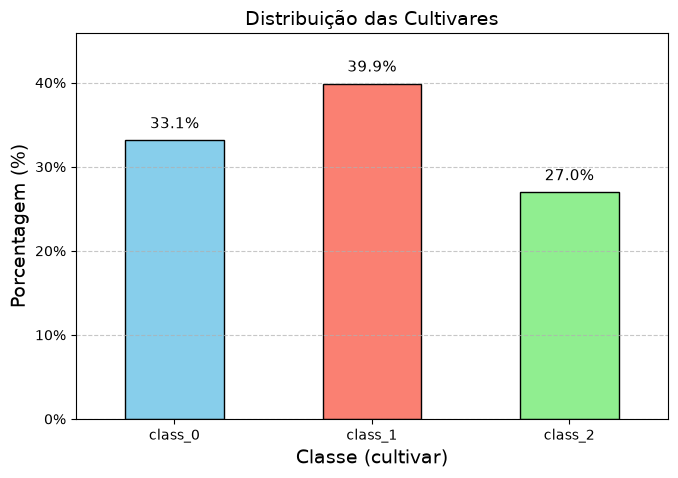

In [7]:
import matplotlib.ticker as mtick

# 1. Calcula as frequências relativas
proporcoes = serie_y.value_counts(normalize=True).sort_index()

plt.figure(figsize=(7, 5))
ax = proporcoes.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'], edgecolor='black')

# 2. Formata o eixo Y para mostrar %
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# 3. Adiciona o valor em porcentagem no topo de cada barra
for i, valor in enumerate(proporcoes):
    ax.text(i, valor + 0.01, f"{valor:.1%}", ha='center', va='bottom', fontsize=11)

plt.title("Distribuição das Cultivares")
plt.xlabel("Classe (cultivar)")
plt.ylabel("Porcentagem (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(proporcoes) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Ordem das amostras**

Primeiros 10 rótulos: [0 0 0 0 0 0 0 0 0 0]
Últimos 10 rótulos:   [2 2 2 2 2 2 2 2 2 2]
Posições em que a classe muda: [ 59 130]


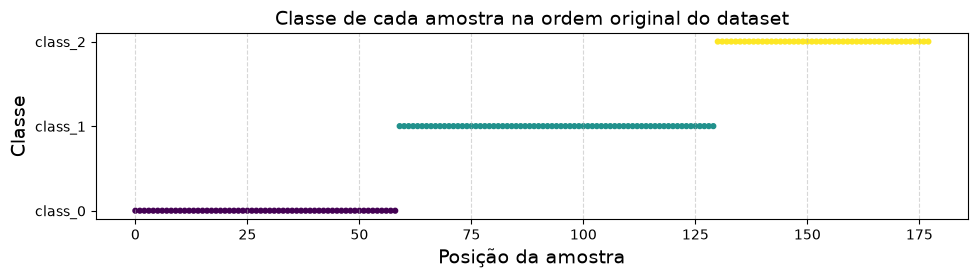

In [8]:
# Primeiros e últimos rótulos e posições em que o rótulo muda
print(f"Primeiros 10 rótulos: {y[:10]}")
print(f"Últimos 10 rótulos:   {y[-10:]}")
print(f"Posições em que a classe muda: {np.where(np.diff(y) != 0)[0] + 1}")

plt.figure(figsize=(10, 3))
plt.scatter(range(len(y)), y, s=12, c=y, cmap='viridis')
plt.yticks([0, 1, 2], wine.target_names)
plt.title("Classe de cada amostra na ordem original do dataset")
plt.xlabel("Posição da amostra")
plt.ylabel("Classe")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## **2.2. Descrição dos Dados**

In [9]:
# Checagem de dados nulos
print(f"Quantidade de dados nulos (NaN) em X: {X.isnull().sum().sum()}")
print(f"Quantidade de dados nulos (NaN) em y: {pd.Series(y).isnull().sum()}")

Quantidade de dados nulos (NaN) em X: 0
Quantidade de dados nulos (NaN) em y: 0


In [10]:
# Escala de cada atributo: mínimo, média, desvio padrão e máximo
X.describe().T[['min', 'mean', 'std', 'max']].round(3)

,min,mean,std,max
alcohol,11.03,13.001,0.812,14.83
malic_acid,0.74,2.336,1.117,5.80
ash,1.36,2.367,0.274,3.23
alcalinity_of_ash,10.60,19.495,3.340,30.00
magnesium,70.00,99.742,14.282,162.00
total_phenols,0.98,2.295,0.626,3.88
flavanoids,0.34,2.029,0.999,5.08
nonflavanoid_phenols,0.13,0.362,0.124,0.66
proanthocyanins,0.41,1.591,0.572,3.58
color_intensity,1.28,5.058,2.318,13.00


**Atributos por classe**

In [11]:
# Média de cada atributo por classe
medias_por_classe = X.groupby(serie_y).mean().T.round(3)

# Variação relativa entre as classes: (maior média - menor média) / desvio padrão do atributo
medias_por_classe['Diferença entre classes (em desvios)'] = (
    (medias_por_classe.max(axis=1) - medias_por_classe.min(axis=1)) / X.std()
).round(2)
medias_por_classe.sort_values('Diferença entre classes (em desvios)', ascending=False)

,class_0,class_1,class_2,Diferença entre classes (em desvios)
flavanoids,2.982,2.081,0.781,2.20
od280/od315_of_diluted_wines,3.158,2.785,1.684,2.08
proline,1115.712,519.507,629.896,1.89
total_phenols,2.840,2.259,1.679,1.86
color_intensity,5.528,3.087,7.396,1.86
alcohol,13.745,12.279,13.154,1.81
hue,1.062,1.056,0.683,1.66
alcalinity_of_ash,17.037,20.238,21.417,1.31
proanthocyanins,1.899,1.630,1.154,1.30
nonflavanoid_phenols,0.290,0.364,0.448,1.27


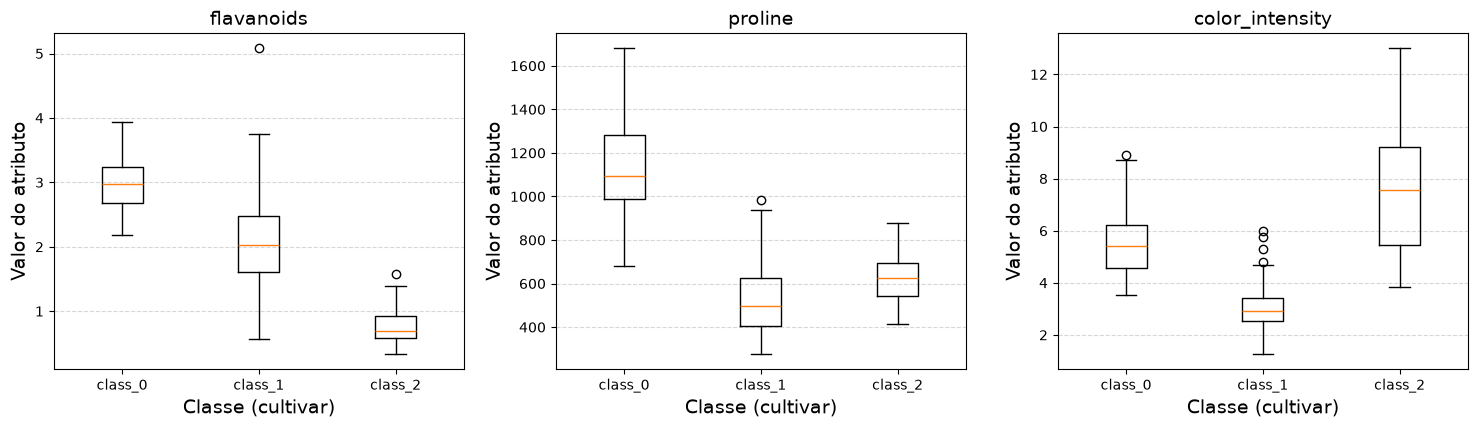

In [12]:
# Distribuição de três atributos em cada classe
atributos_destaque = ['flavanoids', 'proline', 'color_intensity']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, atributo in zip(axes, atributos_destaque):
    valores_por_classe = [X.loc[y == codigo, atributo] for codigo in nomes_classes]
    ax.boxplot(valores_por_classe, tick_labels=list(nomes_classes.values()))
    ax.set_title(atributo)
    ax.set_xlabel("Classe (cultivar)")
    ax.set_ylabel("Valor do atributo")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## **2.3. Separação dos Dados de Treino e Teste**

In [13]:
from sklearn.model_selection import train_test_split

# Divisão COM Estratificação (e com embaralhamento, que é o padrão da função)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Formato do conjunto de treino: {X_train.shape}")
print(f"Formato do conjunto de teste:  {X_test.shape}")

# As amostras foram embaralhadas: as primeiras do treino já não estão agrupadas por classe
print(f"Primeiros 15 rótulos do treino: {y_train[:15]}")

Formato do conjunto de treino: (142, 13)
Formato do conjunto de teste:  (36, 13)
Primeiros 15 rótulos do treino: [0 0 0 0 2 2 1 2 0 0 1 1 0 0 2]


In [14]:
# Quantidade e proporção de cada classe no conjunto completo, no treino e no teste
comparacao_split = pd.DataFrame({
    'Completo': pd.Series(y).map(nomes_classes).value_counts(),
    'Treino': pd.Series(y_train).map(nomes_classes).value_counts(),
    'Teste': pd.Series(y_test).map(nomes_classes).value_counts()
}).sort_index()

print("Quantidade de amostras por classe:")
print(comparacao_split)

print()
print("Proporção de cada classe:")
print((comparacao_split / comparacao_split.sum()).map('{:.2%}'.format))

Quantidade de amostras por classe:
         Completo  Treino  Teste
class_0        59      47     12
class_1        71      57     14
class_2        48      38     10

Proporção de cada classe:
        Completo  Treino   Teste
class_0   33.15%  33.10%  33.33%
class_1   39.89%  40.14%  38.89%
class_2   26.97%  26.76%  27.78%


# **3. Classificação Multiclasse**

In [15]:
# Amostra de exemplo: a primeira do conjunto de treino (a mesma para os quatro modelos)
indice_amostra = 0
amostra = X_train.iloc[[indice_amostra]]

print(f"Classe real da amostra: {nomes_classes[y_train[indice_amostra]]}")

Classe real da amostra: class_0


## **3.1 SGDClassifier**

In [16]:
# Classificador por Gradiente Descendente Estocástico, com padronização no Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

sgd_clf = make_pipeline(
    StandardScaler(),
    SGDClassifier(class_weight='balanced', max_iter=1000, tol=1e-3, random_state=42)
)
sgd_clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('sgdclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [17]:
# Pontuações dos 3 classificadores binários (OvR) para a amostra
scores_sgd = sgd_clf.decision_function(amostra)[0]
classe_sgd = sgd_clf.classes_[np.argmax(scores_sgd)]

print(f"Classificadores binários internos (OvR): {sgd_clf[-1].coef_.shape[0]}")
print(f"Classe escolhida: {nomes_classes[classe_sgd]}")
pd.DataFrame({'Pontuação (decision_function)': scores_sgd.round(2)},
             index=[nomes_classes[c] for c in sgd_clf.classes_])

Classificadores binários internos (OvR): 3
Classe escolhida: class_0


,Pontuação (decision_function)
class_0,35.55
class_1,-57.17
class_2,-97.19


## **3.2 DummyClassifier**

In [18]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train) # não é necessário padronizar

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](3,)","[0.33,0.4 ,0.27]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,13
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [19]:
print(f"Classe escolhida: {nomes_classes[dummy_clf.predict(amostra)[0]]}")
pd.DataFrame({'Probabilidade': dummy_clf.predict_proba(amostra)[0]},
             index=[nomes_classes[c] for c in dummy_clf.classes_])

Classe escolhida: class_1


,Probabilidade
class_0,0.0
class_1,1.0
class_2,0.0


## **3.3 RandomForest**

In [20]:
from sklearn.ensemble import RandomForestClassifier

# n_estimators=100: cria 100 árvores de decisão na floresta
# n_jobs=-1: usa todos os núcleos do processador para acelerar
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest_clf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [21]:
# Proporção de votos das árvores para cada classe
probas_forest = forest_clf.predict_proba(amostra)[0]
classe_forest = forest_clf.classes_[np.argmax(probas_forest)]

print(f"Classe escolhida: {nomes_classes[classe_forest]}")
pd.DataFrame({'Probabilidade (votos)': probas_forest},
             index=[nomes_classes[c] for c in forest_clf.classes_])

Classe escolhida: class_0


,Probabilidade (votos)
class_0,0.98
class_1,0.01
class_2,0.01


## **3.4 Support Vector Classifier**

In [22]:
from sklearn.svm import SVC

# kernel='rbf': fronteiras de decisão não lineares
# gamma='scale': ajusta automaticamente o alcance da influência de cada amostra
svc_clf = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', gamma='scale', random_state=42)
)
svc_clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
# Pontuações agregadas dos duelos (OvO) para a amostra
scores_svc = svc_clf.decision_function(amostra)[0]
classe_svc = svc_clf.classes_[np.argmax(scores_svc)]

n_classes = len(svc_clf.classes_)
print(f"Classificadores binários internos (OvO): {n_classes * (n_classes - 1) // 2}")
print(f"Classe escolhida: {nomes_classes[classe_svc]}")
pd.DataFrame({'Pontuação agregada (decision_function)': scores_svc.round(2)},
             index=[nomes_classes[c] for c in svc_clf.classes_])

Classificadores binários internos (OvO): 3
Classe escolhida: class_0


,Pontuação agregada (decision_function)
class_0,2.23
class_1,0.91
class_2,-0.22


# **4. Avaliação de Performance**

## **4.1 Validação Cruzada**

In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

# Validação cruzada estratificada e embaralhada, reutilizada em todas as avaliações no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Métricas ajustadas para o contexto MULTICLASSE
metricas = {
    'accuracy': 'accuracy',
    'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
    'recall_macro': 'recall_macro',
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
    # usadas só para comparar as formas de média do F1
    'f1_weighted': make_scorer(f1_score, average='weighted', zero_division=0),
    'f1_micro': 'f1_micro',
}

# Nome das métricas principais para exibição
nomes_metricas = {'accuracy': 'Acurácia', 'precision_macro': 'Precisão (macro)',
                  'recall_macro': 'Recall (macro)', 'f1_macro': 'F1-Score (macro)'}

**SGDClassifier**

In [25]:
resultados_sgd = cross_validate(sgd_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica principal nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:18s} {resultados_sgd['test_' + chave].mean():.2%} ± {resultados_sgd['test_' + chave].std():.2%}")

Acurácia           99.29% ± 1.43%
Precisão (macro)   99.26% ± 1.48%
Recall (macro)     99.39% ± 1.21%
F1-Score (macro)   99.29% ± 1.42%


**DummyClassifier**

In [26]:
resultados_dummy = cross_validate(dummy_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica principal nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:18s} {resultados_dummy['test_' + chave].mean():.2%} ± {resultados_dummy['test_' + chave].std():.2%}")

Acurácia           40.12% ± 1.03%
Precisão (macro)   13.37% ± 0.34%
Recall (macro)     33.33% ± 0.00%
F1-Score (macro)   19.09% ± 0.35%


**RandomForest**

In [27]:
resultados_forest = cross_validate(forest_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica principal nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:18s} {resultados_forest['test_' + chave].mean():.2%} ± {resultados_forest['test_' + chave].std():.2%}")

Acurácia           97.91% ± 2.77%
Precisão (macro)   97.85% ± 2.93%
Recall (macro)     98.28% ± 2.25%
F1-Score (macro)   97.89% ± 2.85%


**SVC**

In [28]:
resultados_svc = cross_validate(svc_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica principal nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:18s} {resultados_svc['test_' + chave].mean():.2%} ± {resultados_svc['test_' + chave].std():.2%}")

Acurácia           98.62% ± 1.69%
Precisão (macro)   98.65% ± 1.72%
Recall (macro)     98.78% ± 1.51%
F1-Score (macro)   98.65% ± 1.67%


**F1 macro em cada dobra**

In [29]:
resultados_cv = {
    'Dummy Classifier': resultados_dummy,
    'SGD Classifier': resultados_sgd,
    'Random Forest': resultados_forest,
    'SVC (RBF)': resultados_svc,
}

# F1 macro de cada modelo em cada uma das 5 dobras (mostra a variação entre as divisões)
f1_por_dobra = pd.DataFrame({modelo: res['test_f1_macro'] for modelo, res in resultados_cv.items()},
                            index=[f"Dobra {i}" for i in range(1, 6)])
f1_por_dobra.map('{:.2%}'.format)

,Dummy Classifier,SGD Classifier,Random Forest,SVC (RBF)
Dobra 1,19.51%,100.00%,92.80%,96.33%
Dobra 2,19.51%,100.00%,100.00%,96.91%
Dobra 3,18.80%,100.00%,100.00%,100.00%
Dobra 4,18.80%,100.00%,100.00%,100.00%
Dobra 5,18.80%,96.45%,96.66%,100.00%


**Comparação das formas de média do F1**

In [30]:
# F1 com média macro, ponderada e micro (e a acurácia, para comparar com a micro)
pd.DataFrame({
    modelo: {
        'F1 macro': res['test_f1_macro'].mean(),
        'F1 ponderado': res['test_f1_weighted'].mean(),
        'F1 micro': res['test_f1_micro'].mean(),
        'Acurácia': res['test_accuracy'].mean(),
    }
    for modelo, res in resultados_cv.items()
}).T.map('{:.2%}'.format)

,F1 macro,F1 ponderado,F1 micro,Acurácia
Dummy Classifier,19.09%,22.99%,40.12%,40.12%
SGD Classifier,99.29%,99.29%,99.29%,99.29%
Random Forest,97.89%,97.93%,97.91%,97.91%
SVC (RBF),98.65%,98.62%,98.62%,98.62%


## **4.2 Gráfico Resumo**

In [31]:
# Média de cada métrica principal para cada modelo
df_comparacao = pd.DataFrame({
    modelo: {nome: res['test_' + chave].mean() for chave, nome in nomes_metricas.items()}
    for modelo, res in resultados_cv.items()
}).T
df_comparacao.index.name = 'Modelo'

df_comparacao.map('{:.2%}'.format)

,Acurácia,Precisão (macro),Recall (macro),F1-Score (macro)
Modelo,,,,
Dummy Classifier,40.12%,13.37%,33.33%,19.09%
SGD Classifier,99.29%,99.26%,99.39%,99.29%
Random Forest,97.91%,97.85%,98.28%,97.89%
SVC (RBF),98.62%,98.65%,98.78%,98.65%


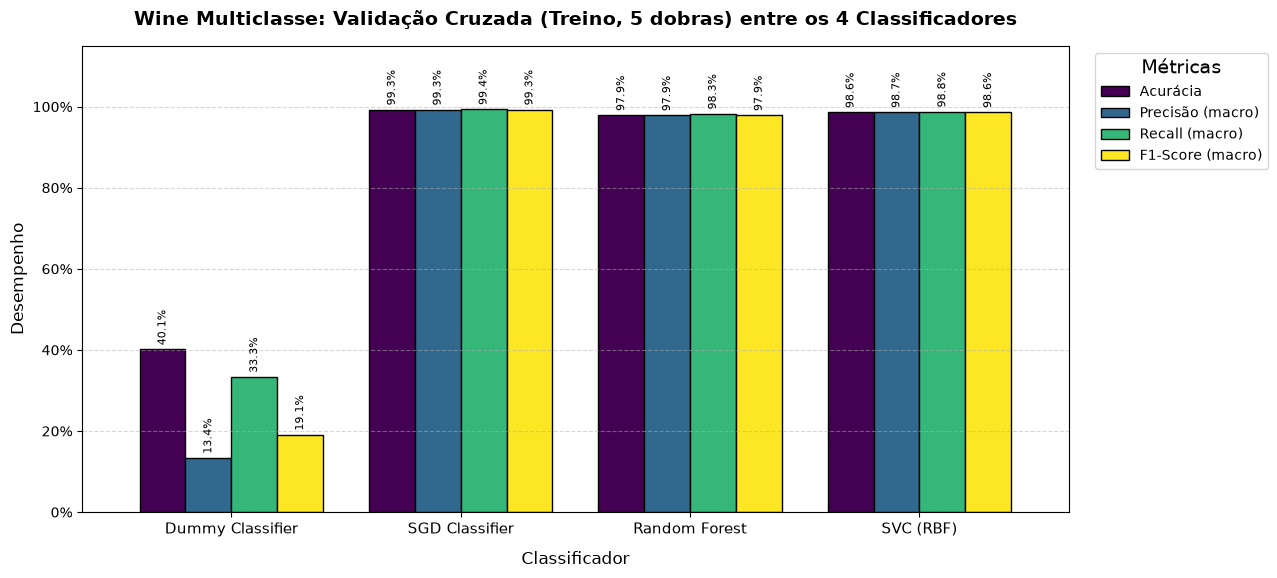

In [32]:
# Configura o tamanho da figura
fig, ax = plt.subplots(figsize=(13, 6))

# Plota o gráfico de barras diretamente do DataFrame
df_comparacao.plot(kind='bar', ax=ax, width=0.8, colormap='viridis', edgecolor='black')

# Estilização do gráfico
plt.title("Wine Multiclasse: Validação Cruzada (Treino, 5 dobras) entre os 4 Classificadores",
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classificador", fontsize=12, labelpad=10)
plt.ylabel("Desempenho", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 1.15)

# Formata o eixo Y para mostrar porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

# Adiciona os valores em porcentagem no topo das barras
for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=90)

plt.tight_layout()
plt.show()

## **4.3 Matrizes de Confusão (Treino, fora da amostra)**

In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

rotulos = list(nomes_classes.values())

# Desenha as 3 versões da matriz de confusão de um modelo, lado a lado
def plot_matrizes_confusao(y_real, y_pred, nome_modelo, conjunto):
    erros = (y_pred != y_real)
    versoes = [
        ("Absoluta", {}),
        ("Relativa", {'normalize': 'true', 'values_format': '.0%'}),
        ("Somente erros", {'sample_weight': erros, 'normalize': 'true', 'values_format': '.0%'}),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, (titulo, opcoes) in zip(axes, versoes):
        ConfusionMatrixDisplay.from_predictions(y_real, y_pred, display_labels=rotulos,
                                                cmap=plt.cm.Blues, colorbar=False, ax=ax, **opcoes)
        ax.set_title(titulo)
        ax.set_xlabel("Classe prevista")
        ax.set_ylabel("Classe real")
    fig.suptitle(f"Matriz de Confusão: {nome_modelo} ({conjunto})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [34]:
# Previsões fora da amostra no treino: cada amostra é prevista por um modelo que não a viu
modelos = {
    'Dummy Classifier': dummy_clf,
    'SGD Classifier': sgd_clf,
    'Random Forest': forest_clf,
    'SVC (RBF)': svc_clf,
}
previsoes_treino = {nome: cross_val_predict(modelo, X_train, y_train, cv=cv)
                    for nome, modelo in modelos.items()}

for nome, y_pred in previsoes_treino.items():
    print(f"{nome:17s} erros fora da amostra: {(y_pred != y_train).sum():3d} de {len(y_train)}")

Dummy Classifier  erros fora da amostra:  85 de 142
SGD Classifier    erros fora da amostra:   1 de 142
Random Forest     erros fora da amostra:   3 de 142
SVC (RBF)         erros fora da amostra:   2 de 142


**SGDClassifier**

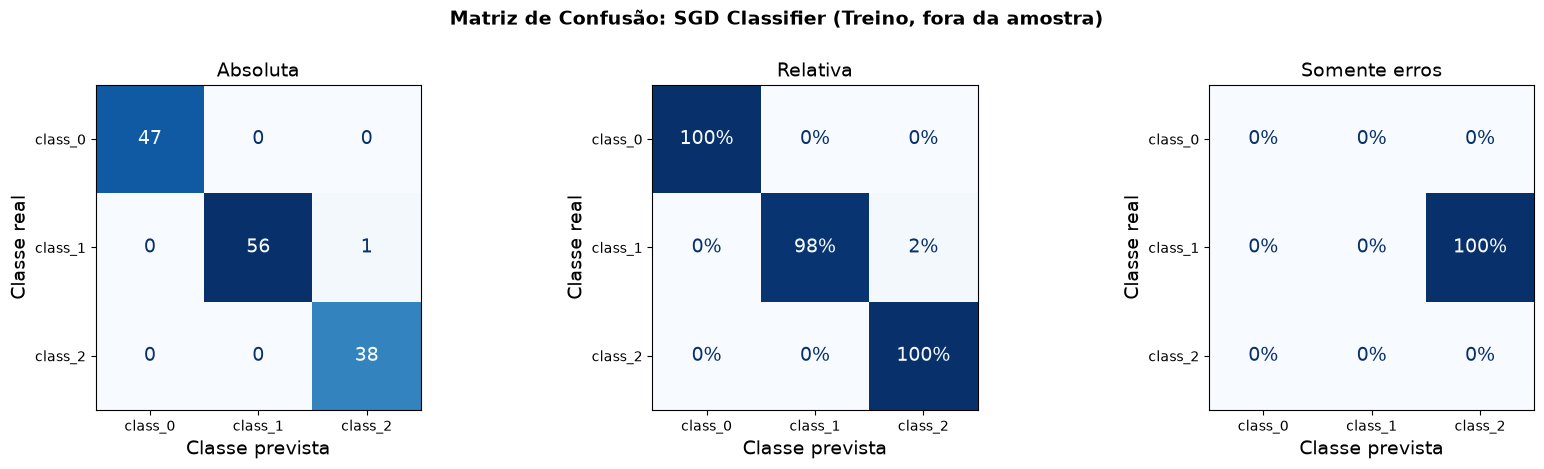

In [35]:
plot_matrizes_confusao(y_train, previsoes_treino['SGD Classifier'], "SGD Classifier", "Treino, fora da amostra")

**DummyClassifier**

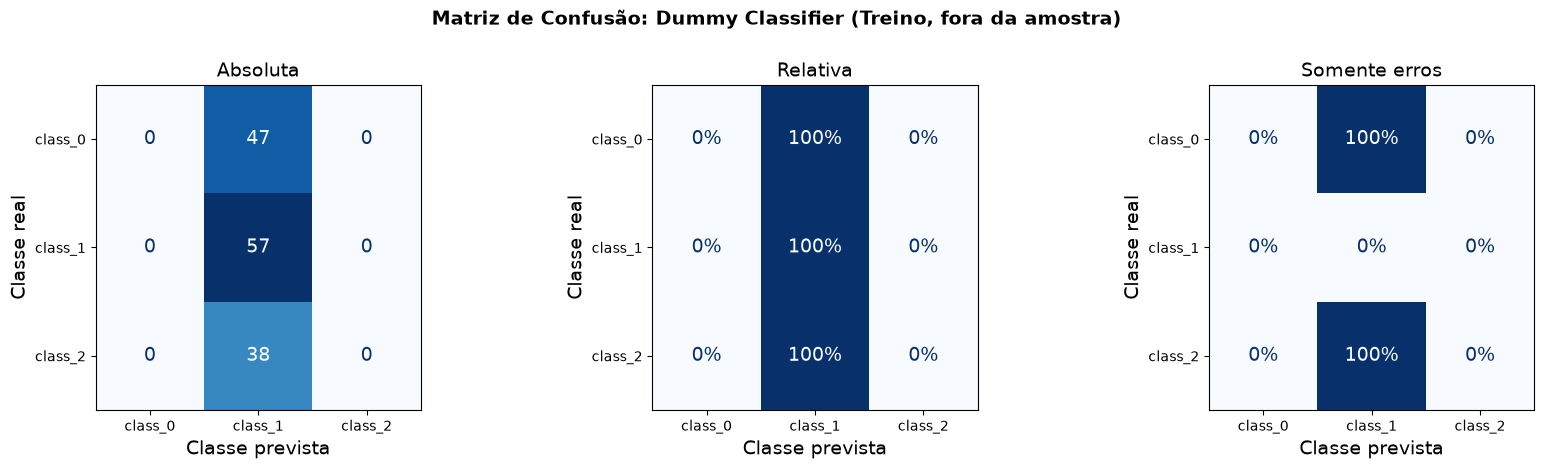

In [36]:
plot_matrizes_confusao(y_train, previsoes_treino['Dummy Classifier'], "Dummy Classifier", "Treino, fora da amostra")

**RandomForest**

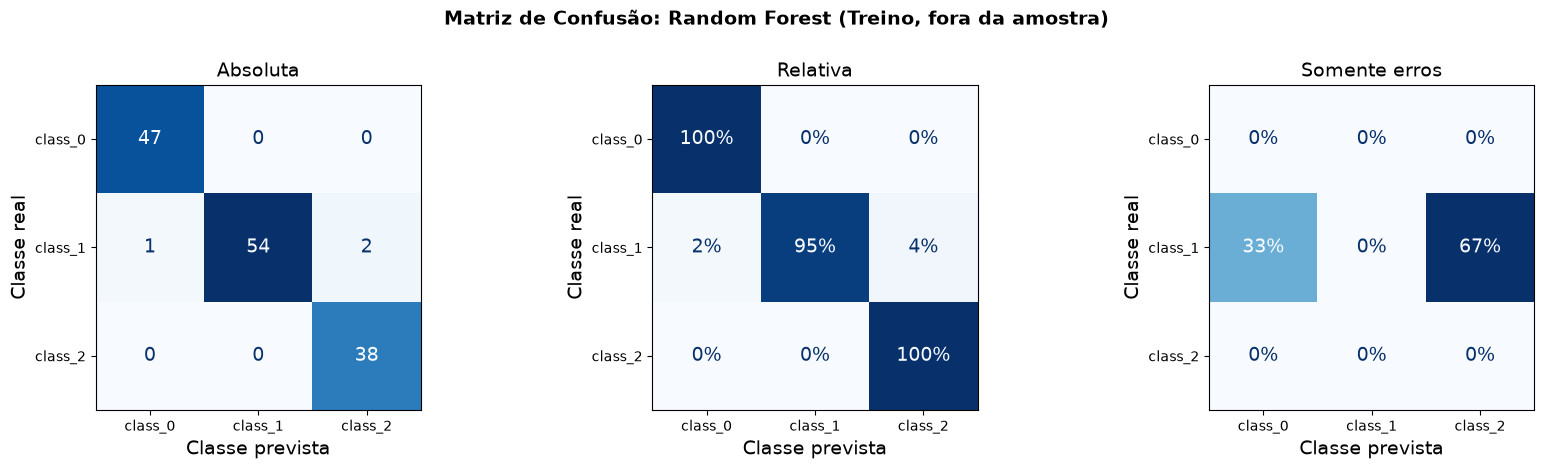

In [37]:
plot_matrizes_confusao(y_train, previsoes_treino['Random Forest'], "Random Forest", "Treino, fora da amostra")

**SVC**

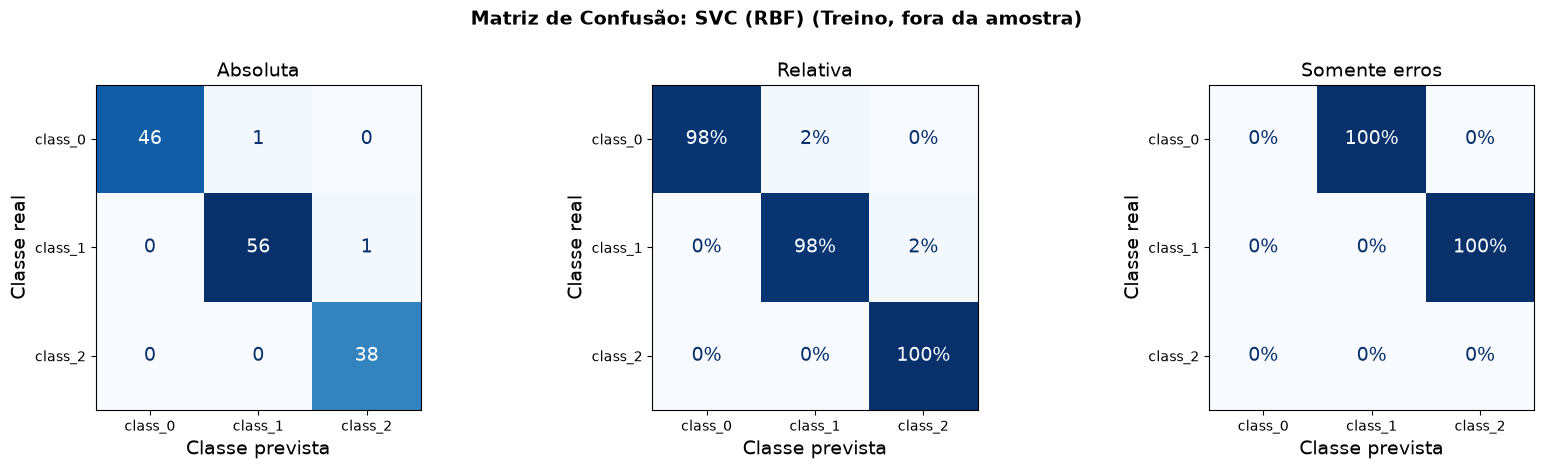

In [38]:
plot_matrizes_confusao(y_train, previsoes_treino['SVC (RBF)'], "SVC (RBF)", "Treino, fora da amostra")

## **4.4 Análise por Classe**

In [39]:
from sklearn.metrics import precision_recall_fscore_support

# Precisão, recall e F1 de cada cultivar para cada modelo (previsões fora da amostra)
linhas = []
for nome, y_pred in previsoes_treino.items():
    precisao, recall, f1, suporte = precision_recall_fscore_support(y_train, y_pred, zero_division=0)
    for codigo, classe in nomes_classes.items():
        linhas.append({'Modelo': nome, 'Classe': classe, 'Precisão': precisao[codigo],
                       'Recall': recall[codigo], 'F1-Score': f1[codigo], 'Amostras': suporte[codigo]})

metricas_por_classe = pd.DataFrame(linhas).set_index(['Modelo', 'Classe'])
metricas_por_classe[['Precisão', 'Recall', 'F1-Score']].map('{:.2%}'.format).join(metricas_por_classe['Amostras'])

Precisão   Recall F1-Score  Amostras
Modelo           Classe                                      
Dummy Classifier class_0    0.00%    0.00%    0.00%        47
                 class_1   40.14%  100.00%   57.29%        57
                 class_2    0.00%    0.00%    0.00%        38
SGD Classifier   class_0  100.00%  100.00%  100.00%        47
                 class_1  100.00%   98.25%   99.12%        57
                 class_2   97.44%  100.00%   98.70%        38
Random Forest    class_0   97.92%  100.00%   98.95%        47
                 class_1  100.00%   94.74%   97.30%        57
                 class_2   95.00%  100.00%   97.44%        38
SVC (RBF)        class_0  100.00%   97.87%   98.92%        47
                 class_1   98.25%   98.25%   98.25%        57
                 class_2   97.44%  100.00%   98.70%        38

In [40]:
# Pares (classe real -> classe prevista) em que os modelos reais erraram
confusoes = []
for nome, y_pred in previsoes_treino.items():
    if nome == 'Dummy Classifier':
        continue
    for real, previsto in zip(y_train, y_pred):
        if real != previsto:
            confusoes.append({'Modelo': nome, 'Classe real': nomes_classes[real],
                              'Classe prevista': nomes_classes[previsto]})

pd.DataFrame(confusoes).value_counts().rename('Erros').to_frame()

Erros
Modelo         Classe real Classe prevista       
Random Forest  class_1     class_2              2
SGD Classifier class_1     class_2              1
Random Forest  class_1     class_0              1
SVC (RBF)      class_0     class_1              1
               class_1     class_2              1

# **5. Teste**

In [41]:
from sklearn.metrics import classification_report, accuracy_score, recall_score

# Acurácia e métricas macro de uma previsão no teste (usada para os quatro modelos)
def metricas_teste(y_pred):
    resultado = {
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão (macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1-Score (macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
    }
    print("-" * 40)
    for nome, valor in resultado.items():
        print(f"{nome:18s} {valor:.2%}")
    print("-" * 40)
    return resultado

## **5.1. SGDClassifier**

In [42]:
print("="*40)
print("     TESTE: SGD CLASSIFIER")
print("="*40)

# Predição (os Pipelines aplicam a padronização aprendida no treino)
y_pred_sgd = modelos['SGD Classifier'].predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_sgd, target_names=rotulos, digits=4, zero_division=0))

# Resumo com agregação macro para multiclasse
teste_sgd = metricas_teste(y_pred_sgd)

     TESTE: SGD CLASSIFIER
              precision    recall  f1-score   support

     class_0     0.9231    1.0000    0.9600        12
     class_1     0.9286    0.9286    0.9286        14
     class_2     1.0000    0.9000    0.9474        10

    accuracy                         0.9444        36
   macro avg     0.9505    0.9429    0.9453        36
weighted avg     0.9466    0.9444    0.9443        36

----------------------------------------
Acurácia           94.44%
Precisão (macro)   95.05%
Recall (macro)     94.29%
F1-Score (macro)   94.53%
----------------------------------------


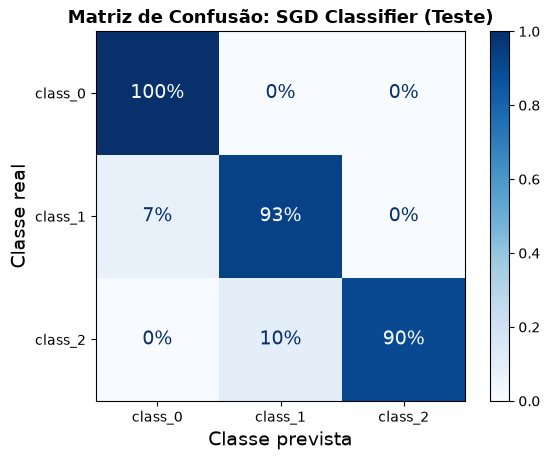

In [43]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sgd, display_labels=rotulos,
                                        normalize="true", values_format=".0%", cmap=plt.cm.Blues)
plt.title("Matriz de Confusão: SGD Classifier (Teste)", fontsize=13, fontweight='bold')
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

## **5.2. DummyClassifier**

In [44]:
print("="*40)
print("     TESTE: DUMMY CLASSIFIER")
print("="*40)

# Predição (os Pipelines aplicam a padronização aprendida no treino)
y_pred_dummy = modelos['Dummy Classifier'].predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_dummy, target_names=rotulos, digits=4, zero_division=0))

# Resumo com agregação macro para multiclasse
teste_dummy = metricas_teste(y_pred_dummy)

     TESTE: DUMMY CLASSIFIER
              precision    recall  f1-score   support

     class_0     0.0000    0.0000    0.0000        12
     class_1     0.3889    1.0000    0.5600        14
     class_2     0.0000    0.0000    0.0000        10

    accuracy                         0.3889        36
   macro avg     0.1296    0.3333    0.1867        36
weighted avg     0.1512    0.3889    0.2178        36

----------------------------------------
Acurácia           38.89%
Precisão (macro)   12.96%
Recall (macro)     33.33%
F1-Score (macro)   18.67%
----------------------------------------


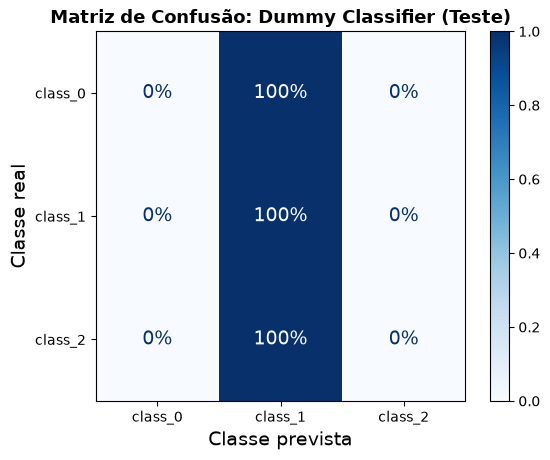

In [45]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dummy, display_labels=rotulos,
                                        normalize="true", values_format=".0%", cmap=plt.cm.Blues)
plt.title("Matriz de Confusão: Dummy Classifier (Teste)", fontsize=13, fontweight='bold')
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

## **5.3. Random Forest**

In [46]:
print("="*40)
print("     TESTE: RANDOM FOREST")
print("="*40)

# Predição (os Pipelines aplicam a padronização aprendida no treino)
y_pred_forest = modelos['Random Forest'].predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_forest, target_names=rotulos, digits=4, zero_division=0))

# Resumo com agregação macro para multiclasse
teste_forest = metricas_teste(y_pred_forest)

     TESTE: RANDOM FOREST
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36

----------------------------------------
Acurácia           100.00%
Precisão (macro)   100.00%
Recall (macro)     100.00%
F1-Score (macro)   100.00%
----------------------------------------


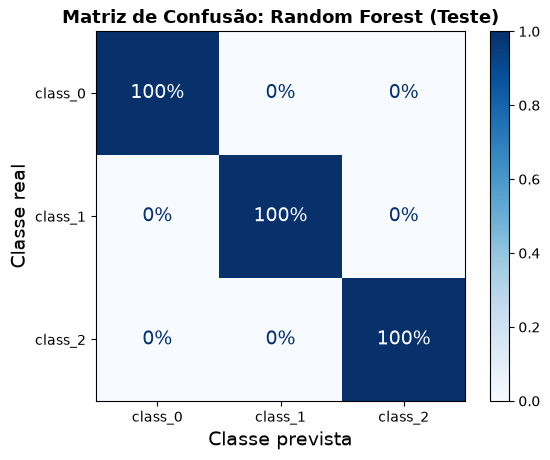

In [47]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_forest, display_labels=rotulos,
                                        normalize="true", values_format=".0%", cmap=plt.cm.Blues)
plt.title("Matriz de Confusão: Random Forest (Teste)", fontsize=13, fontweight='bold')
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

## **5.4. SVC**

In [48]:
print("="*40)
print("     TESTE: SVC")
print("="*40)

# Predição (os Pipelines aplicam a padronização aprendida no treino)
y_pred_svc = modelos['SVC (RBF)'].predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_svc, target_names=rotulos, digits=4, zero_division=0))

# Resumo com agregação macro para multiclasse
teste_svc = metricas_teste(y_pred_svc)

     TESTE: SVC
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     0.9333    1.0000    0.9655        14
     class_2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36

----------------------------------------
Acurácia           97.22%
Precisão (macro)   97.78%
Recall (macro)     96.67%
F1-Score (macro)   97.10%
----------------------------------------


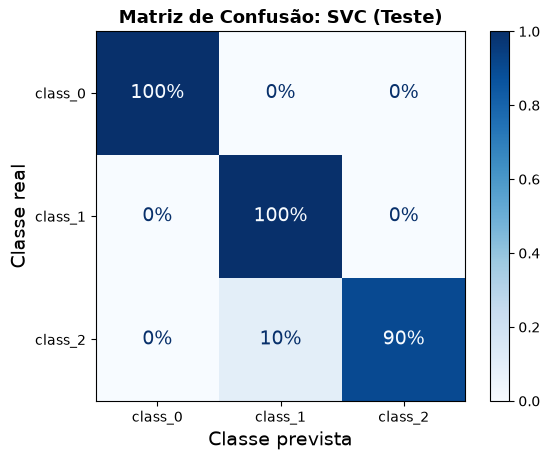

In [49]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svc, display_labels=rotulos,
                                        normalize="true", values_format=".0%", cmap=plt.cm.Blues)
plt.title("Matriz de Confusão: SVC (Teste)", fontsize=13, fontweight='bold')
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

## **5.5. Resumo do Teste**

In [50]:
# Métricas e número de erros de cada modelo no teste
resultados_teste = {
    'Dummy Classifier': (teste_dummy, y_pred_dummy),
    'SGD Classifier': (teste_sgd, y_pred_sgd),
    'Random Forest': (teste_forest, y_pred_forest),
    'SVC (RBF)': (teste_svc, y_pred_svc),
}

df_teste = pd.DataFrame({modelo: metricas for modelo, (metricas, y_pred) in resultados_teste.items()}).T
df_teste['Erros (de 36)'] = [(y_pred != y_test).sum() for metricas, y_pred in resultados_teste.values()]
df_teste.index.name = 'Modelo'

colunas_pct = ['Acurácia', 'Precisão (macro)', 'Recall (macro)', 'F1-Score (macro)']
df_teste[colunas_pct].map('{:.2%}'.format).join(df_teste['Erros (de 36)'].astype(int))

,Acurácia,Precisão (macro),Recall (macro),F1-Score (macro),Erros (de 36)
Modelo,,,,,
Dummy Classifier,38.89%,12.96%,33.33%,18.67%,22
SGD Classifier,94.44%,95.05%,94.29%,94.53%,2
Random Forest,100.00%,100.00%,100.00%,100.00%,0
SVC (RBF),97.22%,97.78%,96.67%,97.10%,1


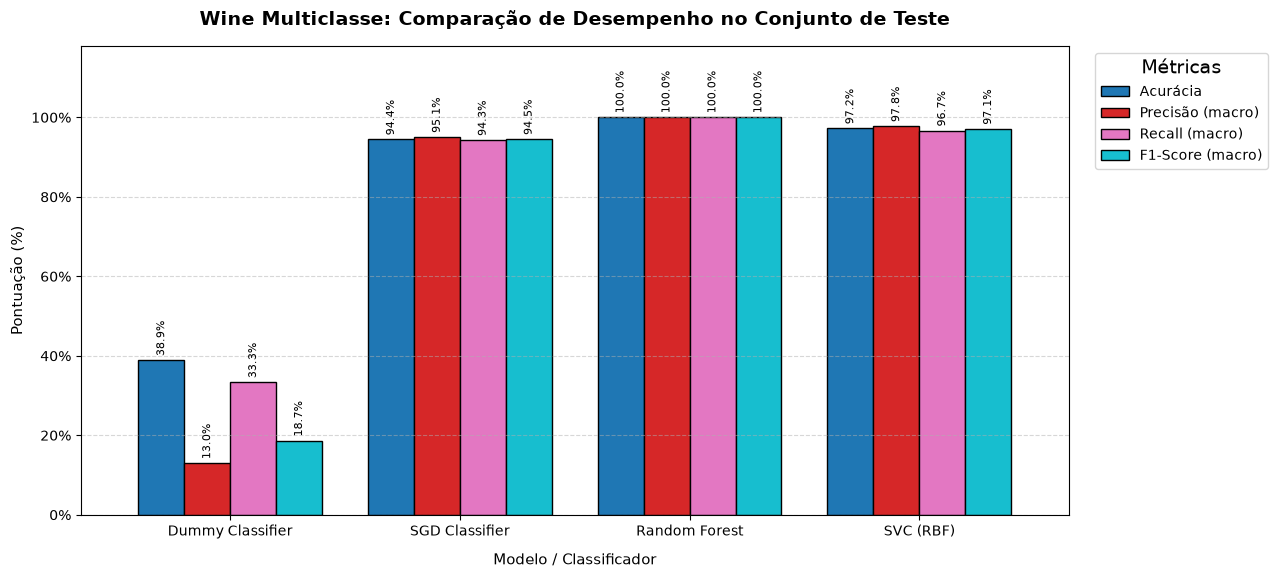

In [51]:
# Configurações do Gráfico
fig, ax = plt.subplots(figsize=(13, 6))

df_teste[colunas_pct].plot(kind="bar", ax=ax, width=0.8, colormap="tab10", edgecolor="black")

# Estilização
plt.title("Wine Multiclasse: Comparação de Desempenho no Conjunto de Teste", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Modelo / Classificador", fontsize=11, labelpad=10)
plt.ylabel("Pontuação (%)", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.ylim(0, 1.18)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Formata o eixo Y em Porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# Adiciona o valor exato em cima de cada barra
for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=90)

plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

# **6. Comparação Final e Conclusão**

In [52]:
# Previsões de cada modelo: (treino fora da amostra, teste)
previsoes_finais = {
    nome: (previsoes_treino[nome], y_pred_teste)
    for nome, y_pred_teste in [('Dummy Classifier', y_pred_dummy), ('SGD Classifier', y_pred_sgd),
                               ('Random Forest', y_pred_forest), ('SVC (RBF)', y_pred_svc)]
}

linhas = []
for modelo, (pred_treino, pred_teste) in previsoes_finais.items():
    for conjunto, y_real, y_pred in [('Treino (validação cruzada)', y_train, pred_treino),
                                     ('Teste', y_test, pred_teste)]:
        linhas.append({
            'Modelo': modelo,
            'Conjunto': conjunto,
            'Acurácia': accuracy_score(y_real, y_pred),
            'Precisão (macro)': precision_score(y_real, y_pred, average='macro', zero_division=0),
            'Recall (macro)': recall_score(y_real, y_pred, average='macro'),
            'F1-Score (macro)': f1_score(y_real, y_pred, average='macro', zero_division=0),
            'Erros': (y_real != y_pred).sum(),
            'Amostras': len(y_real),
        })

df_final = pd.DataFrame(linhas).set_index(['Modelo', 'Conjunto'])

colunas_pct = ['Acurácia', 'Precisão (macro)', 'Recall (macro)', 'F1-Score (macro)']
df_final[colunas_pct].map('{:.2%}'.format).join(df_final[['Erros', 'Amostras']])

Acurácia Precisão (macro)  \
Modelo           Conjunto                                               
Dummy Classifier Treino (validação cruzada)   40.14%           13.38%   
                 Teste                        38.89%           12.96%   
SGD Classifier   Treino (validação cruzada)   99.30%           99.15%   
                 Teste                        94.44%           95.05%   
Random Forest    Treino (validação cruzada)   97.89%           97.64%   
                 Teste                       100.00%          100.00%   
SVC (RBF)        Treino (validação cruzada)   98.59%           98.56%   
                 Teste                        97.22%           97.78%   

                                            Recall (macro) F1-Score (macro)  \
Modelo           Conjunto                                                     
Dummy Classifier Treino (validação cruzada)         33.33%           19.10%   
                 Teste                              33.33%           18.67%   
SGD Classifier   Treino (validação cruzada)         99.42%           99.27%   
                 Teste                              94.29%           94.53%   
Random Forest    Treino (validação cruzada)         98.25%           97.89%   
                 Teste                             100.00%          100.00%   
SVC (RBF)        Treino (validação cruzada)         98.71%           98.62%   
                 Teste                              96.67%           97.10%   

                                             Erros  Amostras  
Modelo           Conjunto                                     
Dummy Classifier Treino (validação cruzada)     85       142  
                 Teste                          22        36  
SGD Classifier   Treino (validação cruzada)      1       142  
                 Teste                           2        36  
Random Forest    Treino (validação cruzada)      3       142  
                 Teste                           0        36  
SVC (RBF)        Treino (validação cruzada)      2       142  
                 Teste                           1        36

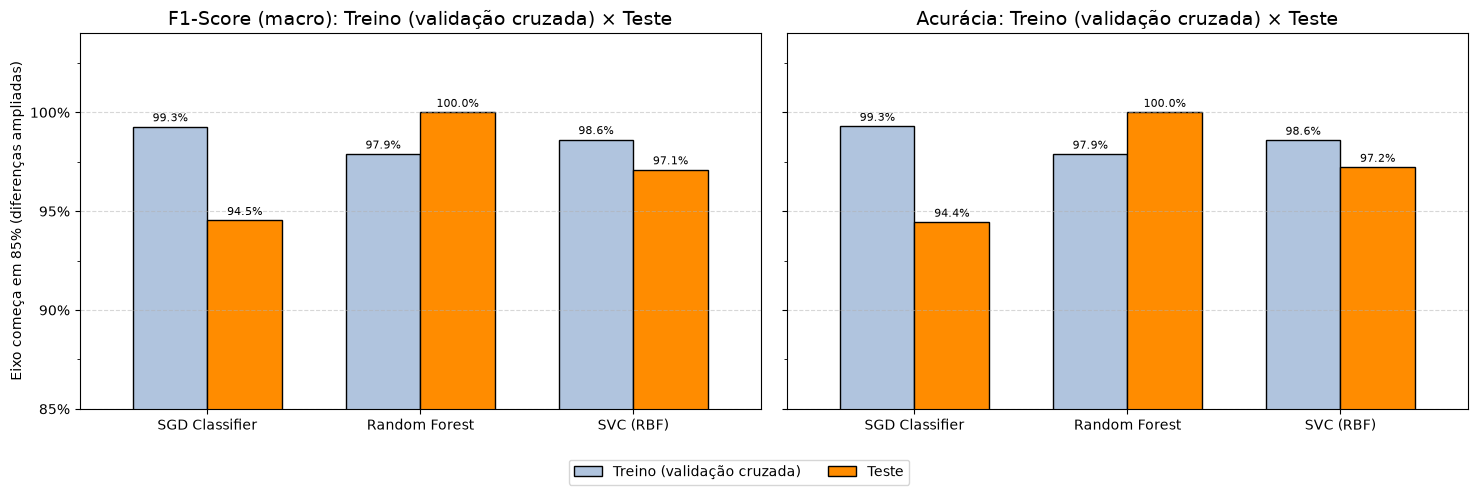

In [53]:
# F1 macro e acurácia no treino (validação cruzada) e no teste, para os modelos reais
modelos_reais = ['SGD Classifier', 'Random Forest', 'SVC (RBF)']

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, metrica in zip(axes, ['F1-Score (macro)', 'Acurácia']):
    tabela = df_final[metrica].unstack('Conjunto').loc[modelos_reais,
                                                       ['Treino (validação cruzada)', 'Teste']]
    tabela.plot(kind='bar', ax=ax, width=0.7, color=['lightsteelblue', 'darkorange'], edgecolor='black')
    ax.set_title(f"{metrica}: Treino (validação cruzada) × Teste")
    ax.set_xlabel("")
    ax.set_ylim(0.85, 1.04)
    ax.set_yticks(np.arange(0.85, 1.001, 0.05))
    ax.set_ylabel("Eixo começa em 85% (diferenças ampliadas)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.get_legend().remove()
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v * 100:.1f}%" for v in container.datavalues],
                     padding=2, fontsize=8)

# Legenda única, abaixo dos dois gráficos (não cobre as barras)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=10)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()